In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math
import pandas as pd
from scipy.optimize import curve_fit

In [118]:
df=pd.read_csv("advertising.csv")

In [ ]:
df.head()

## initial data inspection

In [192]:
df.isnull().sum()

TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

In [ ]:
df.duplicated().sum()

In [ ]:
#df.describe()

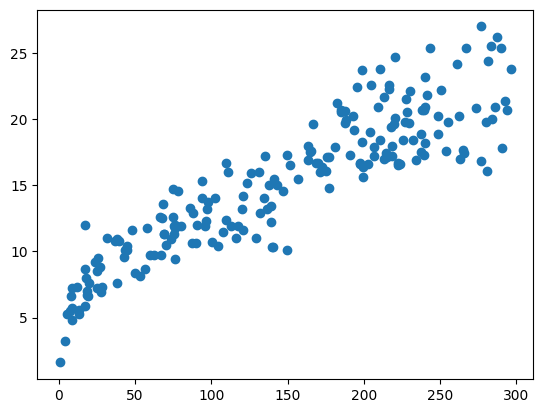

In [138]:
plt.scatter(df.TV,df.Sales)

## Exploratory Data analysis(EDA)

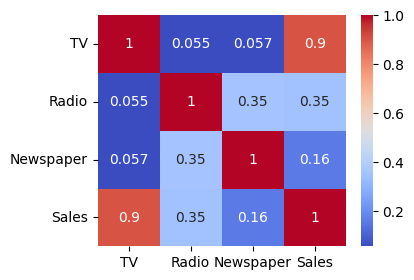

In [193]:
import seaborn as sns
plt.figure(figsize=(4,3))
sns.heatmap(df.corr(),annot=True,cmap='coolwarm')
plt.show()

In [ ]:
sns.pairplot(df)
plt.show()

##  Defining the Nonlinear Regression Function

In [98]:
def loga(x,a,b,c):
    y=a*np.log(x+b)+c
    return y    

In [84]:
def da2(x,d,e,f,):
    y=d*(x**2) + e*(x) + f
    return y        

'def da2(x,d,e,f,):\n    y=d*(x**2) + e*(x) + f\n    return y    \n'

In [101]:
def nonlinear(x,a,b,c,d,e,f):
    x1=x[:,0]
    x2=x[:,1]
    ymodel=loga(x1,a,b,c)+da2(x2,d,e,f)
    return(ymodel)     

'def nonlinear(x,a,b,c,d,e,f):\n    x1=x[:,0]\n    x2=x[:,1]\n    ymodel=loga(x1,a,b,c)+da2(x2,d,e,f)\n    return(ymodel) \n'

## train test split

In [177]:
from sklearn.model_selection import train_test_split
# Sample data
X=df[['TV','Radio']]
Y =df['Sales']
# Splitting data into training and testing sets
x_train, x_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=42)
len(y_test)

40

In [178]:
xtrain1=x_train["TV"].to_numpy()
xtrain2=x_train["Radio"].to_numpy()
ytrain=y_train.to_numpy()
xtrain=np.column_stack((xtrain1,xtrain2))
xtest1=x_test["TV"].to_numpy()
xtest2=x_test["Radio"].to_numpy()
xtest=np.column_stack((xtest1,xtest2))
ytest=y_test.to_numpy()
len(xtest)

40

## estimating parameters

In [179]:
popt, pcov = curve_fit(nonlinear,xtrain, ytrain)
print(popt)

[ 3.42807021e-07 -2.51343979e-04  1.01556821e-01 -6.81703472e+08
  1.05575776e-04 -6.00337431e-03  1.74853075e-01  6.81703475e+08]


## model evaluation

In [180]:
from sklearn.metrics import r2_score
from sklearn.metrics import mean_squared_error
y_train_pred=nonlinear(xtrain,*popt)
r2_train=r2_score(ytrain,y_train_pred)
print("R2-scoretrain: %.3f" % r2_score(ytrain , y_train_pred) )
print("Mean absolute error: %.3f" % np.mean(np.absolute(y_train_pred-ytrain)))
print("Mean squared error (MSE): %.3f" % np.mean((y_train_pred-ytrain) ** 2))
rmse = np.sqrt(mean_squared_error(ytrain,y_train_pred))
print("rmse: %.3f" %rmse)
len(y_train_pred)

R2-scoretrain: 0.922
Mean absolute error: 1.109
Mean squared error (MSE): 2.101
rmse: 1.449


160

In [181]:
from sklearn.metrics import r2_score
from sklearn.metrics import mean_squared_error
y_pred = nonlinear(xtest,*popt)
print("Mean absolute error: %.3f" % np.mean(np.absolute(y_pred-ytest)))
print("Mean squared error (MSE): %.3f" % np.mean((y_pred-ytest) ** 2))
print("R2-score: %.3f" % r2_score(ytest , y_pred) )
rmse = np.sqrt(mean_squared_error(ytest,y_pred))
print("rmse: %.3f" %rmse)
len(y_pred)

Mean absolute error: 0.919
Mean squared error (MSE): 1.619
R2-score: 0.948
rmse: 1.273


40

## cross validation

In [182]:
from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy.optimize import curve_fit
import numpy as np

kf = KFold(n_splits=5, shuffle=True, random_state=42)

mae_scores = []
mse_scores = []
rmse_scores = []
r2_scores = []

for train_idx, val_idx in kf.split(x_train):

    X_train_cv = x_train.iloc[train_idx]
    X_val_cv = x_train.iloc[val_idx]

    y_train_cv = y_train.iloc[train_idx]
    y_val_cv = y_train.iloc[val_idx]

    # تخمین پارامترها فقط با داده‌های Train این Fold
    params, _ = curve_fit(
        nonlinear,
        X_train_cv.values,
        y_train_cv.values
    )

    # پیش‌بینی روی Validation
    y_predict = nonlinear(
        X_val_cv.values,
        *params
    )

    # ارزیابی
    mae_scores.append(
        mean_absolute_error(y_val_cv, y_predict)
    )

    mse_scores.append(
        mean_squared_error(y_val_cv, y_predict)
    )

    rmse_scores.append(
        np.sqrt(mean_squared_error(y_val_cv, y_predict))
    )

    r2_scores.append(
        r2_score(y_val_cv, y_predict)
    )    

40

In [194]:
for fold, (train_idx, val_idx) in enumerate(kf.split(x_train), start=1):

    X_train_cv = x_train.iloc[train_idx]
    X_val_cv = x_train.iloc[val_idx]

    y_train_cv = y_train.iloc[train_idx]
    y_val_cv = y_train.iloc[val_idx]

    params, _ = curve_fit(
        nonlinear,
        X_train_cv.values,
        y_train_cv.values
    )

    y_predict = nonlinear(X_val_cv.values, *params)

    r2 = r2_score(y_val_cv, y_predict)

    print(f"Fold {fold}:")
    print("R2 =", r2)
    print("MAE =", mean_absolute_error(y_val_cv, y_predict))
    print("MSE =", mean_squared_error(y_val_cv, y_predict))
    print( "RMSE =", np.sqrt(mean_squared_error(y_val_cv, y_predict)))
    print("Std y:", y_val_cv.std())
    print("Validation samples =", len(y_val_cv))
    print("y mean:", y_val_cv.mean())
    print("y min:", y_val_cv.min())
    print("y max:", y_val_cv.max())
    print("Actual:")
    print(y_val_cv.values)
    print("\nPredicted:")
    print(y_predict)
    print("\nError:")
    print(y_val_cv.values - y_predict)
    print() 

Fold 1:
R2 = 0.7888075653911921
MAE = 1.3962787441909312
MSE = 3.2870782494144635
RMSE = 1.8130301292075826
Std y: 4.008297844834291
Validation samples = 32
y mean: 13.9
y min: 7.2
y max: 22.6
Actual:
[12.   7.2 11.  10.9  7.6 16.7 17.8  9.5 10.7 11.9 19.2 17.3 12.9 12.6
 15.2 18.  17.  17.9 15.  21.2 15.5 16.8 11.8 11.9  7.3 14.  12.9  9.7
 22.6 10.1 12.2 18.4]

Predicted:
[11.51247609 10.9667145  13.23994756 10.84126103  6.73498821 16.1927017
 20.33273578  9.10577726 12.0768162   8.98949313 18.7861824  16.71049774
 14.49350846  9.27562058 15.13008118 17.60528827 19.00987899 17.40285921
 19.01973569 21.15540433 14.06591022 19.34164286 11.47085679 10.37100399
  5.4639008  11.02071476 12.20199311  9.54133272 21.14878511  9.08275783
 14.69051051 18.51931572]

Error:
[ 0.48752391 -3.7667145  -2.23994756  0.05873897  0.86501179  0.5072983
 -2.53273578  0.39422274 -1.3768162   2.91050687  0.4138176   0.58950226
 -1.59350846  3.32437942  0.06991882  0.39471173 -2.00987899  0.49714079
 -4.019

## 3D Visualization of Model Predictions on Training and Test Data

In [ ]:
TV_grid = np.linspace(x_train["TV"].min(), x_train["TV"].max(), 50)
Radio_grid = np.linspace(x_train["Radio"].min(), x_train["Radio"].max(), 50)
TV_mesh, Radio_mesh = np.meshgrid(TV_grid, Radio_grid)
X_grid = np.column_stack((
    TV_mesh.ravel(),
    Radio_mesh.ravel()
))
Sales_pred = nonlinear(X_grid, *popt)
Sales_mesh = Sales_pred.reshape(TV_mesh.shape)

In [ ]:
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection="3d")
# داده‌های واقعی
ax.scatter(
    x_train["TV"],
    x_train["Radio"],
    y_train
)
# سطح مدل
ax.plot_surface(
    TV_mesh,
    Radio_mesh,
    Sales_mesh,
    alpha=0.5
)
ax.set_xlabel("TV")
ax.set_ylabel("Radio")
ax.set_zlabel("Sales")
plt.show()

In [ ]:
TV_grid = np.linspace(x_test["TV"].min(), x_test["TV"].max(), 50)
Radio_grid = np.linspace(x_test["Radio"].min(), x_test["Radio"].max(), 50)
TV_mesh, Radio_mesh = np.meshgrid(TV_grid, Radio_grid)
X_grid = np.column_stack((
    TV_mesh.ravel(),
    Radio_mesh.ravel()
))
Sales_pred = nonlinear(X_grid, *popt)
Sales_mesh = Sales_pred.reshape(TV_mesh.shape)

In [ ]:
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection="3d")
# داده‌های واقعی
ax.scatter(
    x_test["TV"],
    x_test["Radio"],
    y_test
)
# سطح مدل
ax.plot_surface(
    TV_mesh,
    Radio_mesh,
    Sales_mesh,
    alpha=0.5
)
ax.set_xlabel("TV")
ax.set_ylabel("Radio")
ax.set_zlabel("Sales")
plt.show()

## Residual analysis

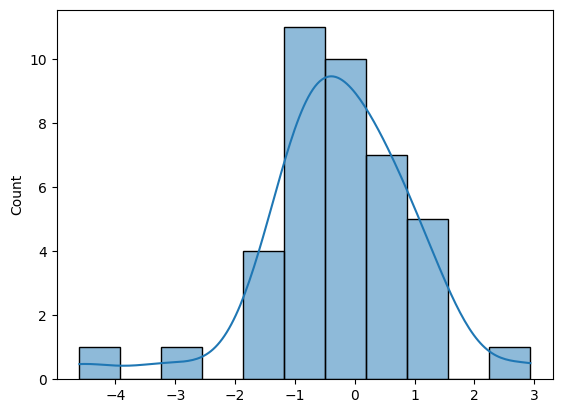

In [189]:
import seaborn as sns
residuals = ytest - y_pred
sns.histplot(residuals,kde=True)
plt.show()

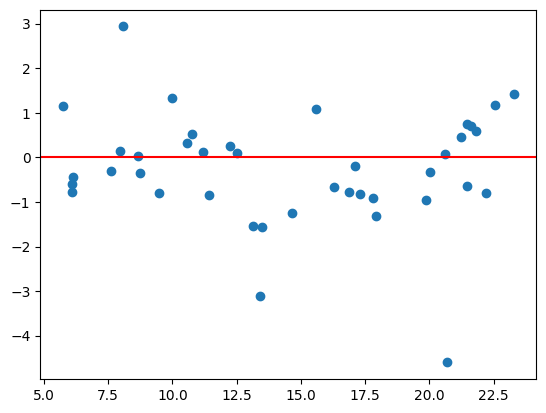

In [190]:
plt.scatter(y_pred,residuals)
plt.axhline(y=0,color='red')
plt.show()